# OCR DETECTION (NUXIA PROJECT)
Pipeline: imagen → filtro (OpenCV) → PaddleOCR → `funcion_maestra` (regex) → métricas.

## 1. Import libraries and dependancies

In [ ]:
# Only if needed: 
#!pip install paddleocr
#!pip install paddlepaddle

In [2]:
import json, re, time
from datetime import date
from difflib import SequenceMatcher
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from paddleocr import PaddleOCR

# --- Rutas y datos ---
CARPETA_MUESTRA = Path("muestra_15_imagenes")
ARCHIVO_OCR = CARPETA_MUESTRA / "resultados_ocr_unificado.csv"
Path("figuras").mkdir(exist_ok=True)

rutas_imagenes = sorted(
    r for r in CARPETA_MUESTRA.iterdir()
    if r.is_file() and r.suffix.lower() in {".png", ".jpg", ".jpeg"}
)
assert len(rutas_imagenes) == 15, f"Se esperaban 15 imágenes y hay {len(rutas_imagenes)}"

c:\Users\paula\anaconda3\envs\ml2025\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.7.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


## Data Structure

/main 


//pruebas,//pruebas,//pruebas

//data_train (entrenar el classifier)
//data_all (divididas en troqueladas y no con sus previos análisis)

## 2. Motor OCR

In [3]:
paddle_ocr = PaddleOCR(
    lang="es",
    use_angle_cls=True,
    enable_mkldnn=False,                          # language (o "en", "ch", etc.)
    use_doc_orientation_classify=False, # desactiva módulos extra para ir más rápido
    use_doc_unwarping=False
)

C:\Users\paula\AppData\Local\Temp\ipykernel_5924\3178821793.py:1: DeprecationWarning: The parameter `use_angle_cls` has been deprecated and will be removed in the future. Please use `use_textline_orientation` instead.
  paddle_ocr = PaddleOCR(
c:\Users\paula\anaconda3\envs\ml2025\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\paula\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\paula\.paddlex\official_mod

 Imágenes para utilizar (Copiar y pegar) en path_img = Path("pruebas14082026/1b4df212")

- 1a0b72b0 (Diferente formato) - Tiene que extraer todo
- 1a3b95bb (Troquelada) - No se extrae nada
- 1aaa2407 (Diferente formato) - Tiene que extraer todo
- 1b4df212 (Diferente formato) - Tiene que extraer todo
- 2b733ecd (Diferente formato) - Tiene que extraer todo
- 2c9787d9 (Diferente formato) - Tiene que extraer todo
- 4d95d836 (Diferente formato) - Tiene que extraer todo

 Problemas:

- 1a0b72b0 - Junta dos líneas de texto
- 1a3b95bb
- 1aaa2407 - Lote: en Lote1 y vcto: en uct01. Los dos puntos los convierte en un 1
- 1b4df212 - Está rotada y no entiende bien el número de lote
- 2b733ecd - Junta dos líneas de texto
- 2c9787d9 - "Lote N° :"
- 4d95d836 - LOTE:, y FP Y FE

- ¿Cómo lidiar con rotadas? use_angle_cls=True
- Junta dos cadenas de texto (arriba y abajo en una)
- Convierte dos puntos en "1"

In [4]:
def extraer_texto_paddle(ocr, imagen):
    textos = []
    predecir = getattr(ocr, "predict", None)

    if callable(predecir):
        predicciones = predecir(imagen)
        for pagina in predicciones:
            datos = pagina.json if hasattr(pagina, "json") else pagina
            if callable(datos):
                datos = datos()
            if isinstance(datos, str):
                datos = json.loads(datos)
            if isinstance(datos, dict):
                datos = datos.get("res", datos)
                if isinstance(datos, dict):
                    textos.extend(str(texto) for texto in datos.get("rec_texts", []))
    else:
        predicciones = ocr.ocr(imagen, cls=True)
        for pagina in predicciones:
            if not pagina:
                continue
            for linea in pagina:
                if len(linea) > 1 and isinstance(linea[1], (tuple, list)):
                    textos.append(str(linea[1][0]))

    return textos

## 3. Extracción de campos (`funcion_maestra`)
Recibe el texto bruto del OCR y devuelve `lote`, `fecha_fabricacion` y `fecha_caducidad` (formato AAAA-MM).

In [5]:
def funcion_maestra(texto):

    resultado = {
        "lote": None,
        "fecha_fabricacion": None,
        "fecha_caducidad": None
    }

    # ------------------------------------------------------------------
    # Configuración: para otros idiomas o medicamentos, amplía estos conjuntos
    # (en mayúsculas, sin espacios ni símbolos, y con O en lugar de 0)
    # ------------------------------------------------------------------
    ETIQ_LOTE = ["LOT", "LOTE", "BATCH", "LOTNO", "LOTNR"]
    ETIQ_FAB = ["MANUF", "MANUFACTURED", "MFG", "MFD", "MAN", "FAB", "FABRICACION", "PROD"]
    ETIQ_CAD = ["EXP", "EXF", "EXPIRY", "EXPIRES", "CAD", "CADUCIDAD", "USEBY"]

    patron_valor = re.compile(r"[A-Z0-9][A-Z0-9./_-]*", re.IGNORECASE)
    patron_pegado = re.compile(r"^(?:LOTE|LOT|BATCH)[.\-/]?([A-Z0-9][A-Z0-9./_-]*)$", re.IGNORECASE)

    patron_fecha = re.compile(
        r"(?<![\d/.\-])(?:"
        r"(?P<y5>\d{4})[/.\-](?P<m5>\d{1,2})[/.\-](?P<d5>\d{1,2})"         # aaaa/mm/dd
        r"|(?P<d>\d{1,2})[/.\-](?P<m1>\d{1,2})[/.\-](?P<y1>\d{4}|\d{2})"   # dd/mm/aaaa o dd/mm/aa
        r"|(?P<y2>\d{4})[/.\-](?P<m2>\d{1,2})"                              # aaaa-mm
        r"|(?P<m3>\d{1,2})[/.\-](?P<y3>\d{4})"                              # mm/aaaa
        r"|(?<![A-Za-z])(?P<m6>\d{1,2})/(?P<y6>\d{2})"                      # mm/aa (solo con "/")
        r"|(?P<m4>\d{1,2}) (?P<y4>\d{4})"                                   # mm aaaa
        r")(?![\d/.\-])"
    )

    # ------------------------------------------------------------------
    # 1. LOTE
    # ------------------------------------------------------------------
    lineas = [l.strip() for l in texto.splitlines() if l.strip()]

    # Para cada línea se guarda una lista de tokens con sus características:
    # (texto, es_etiqueta_lote, es_valor_lote, valor_pegado_a_etiqueta)
    info_lineas = []
    for linea in lineas:
        partes = re.split(r"[\s:：#=;,]+", linea)
        toks = [p.strip(" .°º") for p in partes if p.strip(" .°º")]

        info = []
        for t in toks:
            # ¿Es una etiqueta de lote (aproximada)?
            norm_t = re.sub(r"[^A-Z0-9]", "", t.upper()).replace("0", "O")
            sim_t = 0.0
            if norm_t:
                sim_t = max(SequenceMatcher(None, norm_t, e).ratio() for e in ETIQ_LOTE)
            es_etiqueta = sim_t >= 0.8

            # ¿Es un valor de lote válido? Se evalúa el token y, si la etiqueta
            # viene pegada al valor (LOT123), también el valor pegado.
            m_pegado = patron_pegado.match(t)
            pegado = m_pegado.group(1) if m_pegado else None

            flags = []
            for c in (t, pegado):
                if c is None:
                    flags.append(False)
                    continue
                norm_c = re.sub(r"[^A-Z0-9]", "", c.upper()).replace("0", "O")
                sim_c = 0.0
                if norm_c:
                    sim_c = max(SequenceMatcher(None, norm_c, e).ratio() for e in ETIQ_LOTE)
                flags.append(
                    patron_valor.fullmatch(c) is not None
                    and len(c) >= 3
                    and any(ch.isdigit() for ch in c)
                    and patron_fecha.fullmatch(c) is None
                    and sim_c < 0.8
                )
            es_valor, pegado_valido = flags

            info.append((t, es_etiqueta, es_valor, pegado if pegado_valido else None))
        info_lineas.append(info)

    lote = None
    for i, info in enumerate(info_lineas):
        for k, (t, es_etiqueta, es_valor, pegado) in enumerate(info):
            # Etiqueta pegada al valor: LOT123, LOTE-ABC12, BATCH.5567
            if pegado:
                lote = pegado
                break

            if not es_etiqueta:
                continue

            # Candidatos por orden de prioridad:
            # a) mismo renglón: después de la etiqueta y luego antes
            # b) líneas siguientes (hasta 3)
            # c) líneas anteriores (hasta 2), valor impreso antes de la etiqueta
            candidatos = [x[0] for x in info[k + 1:] if x[2]]
            candidatos += [x[0] for x in info[:k][::-1] if x[2]]
            for j in range(i + 1, min(i + 4, len(info_lineas))):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]
            for j in range(i - 1, max(i - 3, -1), -1):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]

            if candidatos:
                lote = candidatos[0]
                break

            # Plan B: no hay etiqueta, se busca un código que parezca un lote
    if lote is None:
        patron_unidad = re.compile(
            r"^\d+([.,]\d+)?(MG|ML|G|MCG|UG|UI|IU|KG|L|MM|CM)$", re.IGNORECASE
        )
        for info in info_lineas:
            for t, es_etiqueta, es_valor, pegado in info:
                if (
                    es_valor                                  # alfanumérico, con dígito, no es fecha ni etiqueta
                    and len(t) >= 4
                    and any(c.isalpha() for c in t)           # mezcla letras y números
                    and not patron_unidad.match(t)            # descarta dosis: 500MG, 10ML...
                ):
                    lote = t
                    break
            if lote:
                break

    resultado["lote"] = lote

    # ------------------------------------------------------------------
    # 2. FECHAS
    # ------------------------------------------------------------------
    fechas = []  # (año, mes, inicio, fin)
    for m in patron_fecha.finditer(texto):
        g = m.groupdict()
        if g["y5"]:
            mes, anio = int(g["m5"]), g["y5"]
        elif g["d"]:
            mes, anio = int(g["m1"]), g["y1"]
        elif g["y2"]:
            mes, anio = int(g["m2"]), g["y2"]
        elif g["m3"]:
            mes, anio = int(g["m3"]), g["y3"]
        elif g["m6"]:
            mes, anio = int(g["m6"]), g["y6"]
        else:
            mes, anio = int(g["m4"]), g["y4"]

        anio = int(anio) + (2000 if len(anio) == 2 else 0)
        if 1 <= mes <= 12 and 2000 <= anio <= 2100:
            fechas.append((anio, mes, m.start(), m.end()))

    unicas = sorted({(a, mes) for a, mes, _, _ in fechas})
    fab = cad = None

    if len(unicas) >= 2:
        # El orden cronológico no depende de lo bien que el OCR lea las etiquetas
        fab, cad = unicas[0], unicas[-1]

    elif len(unicas) == 1:
        a, mes, ini, fin = fechas[0]
        tipo = None

        # Palabras cercanas: primero las anteriores a la fecha, luego las posteriores
        antes = re.findall(r"[A-Za-z0-9]+", texto[max(0, ini - 25):ini])[-2:]
        despues = re.findall(r"[A-Za-z0-9]+", texto[fin:fin + 25])[:2]
        for palabra in list(reversed(antes)) + despues:
            if palabra.isdigit():
                continue
            norm_p = re.sub(r"[^A-Z0-9]", "", palabra.upper()).replace("0", "O")
            if not norm_p:
                continue
            sc_cad = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_CAD)
            sc_fab = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_FAB)
            if max(sc_cad, sc_fab) >= 0.5:
                tipo = "cad" if sc_cad >= sc_fab else "fab"
                break

        # Sin etiqueta fiable: si es futura se asume caducidad, si no, fabricación
        if tipo is None:
            hoy = date.today()
            tipo = "cad" if (a, mes) >= (hoy.year, hoy.month) else "fab"

        if tipo == "cad":
            cad = (a, mes)
        else:
            fab = (a, mes)

    resultado["fecha_fabricacion"] = f"{fab[0]}-{fab[1]:02d}" if fab else None
    resultado["fecha_caducidad"] = f"{cad[0]}-{cad[1]:02d}" if cad else None

    return resultado

### 3.1 Ejemplo paso a paso con una imagen (opcional)
Esta sección **no forma parte del experimento ni de las métricas**. Sirve para ver, con una sola imagen, qué hace cada paso del pipeline:
1. Se carga la imagen original (sin filtros).
2. PaddleOCR detecta y reconoce el texto.
3. Se guarda la imagen con las cajas dibujadas y un JSON con los textos y coordenadas.
4. Se unen las líneas de texto en un solo bloque.
5. `funcion_maestra` extrae lote, fecha de fabricación y fecha de caducidad.

Es útil para entender el pipeline, para enseñar un caso en el informe y para depurar imágenes en las que `funcion_maestra` falla.

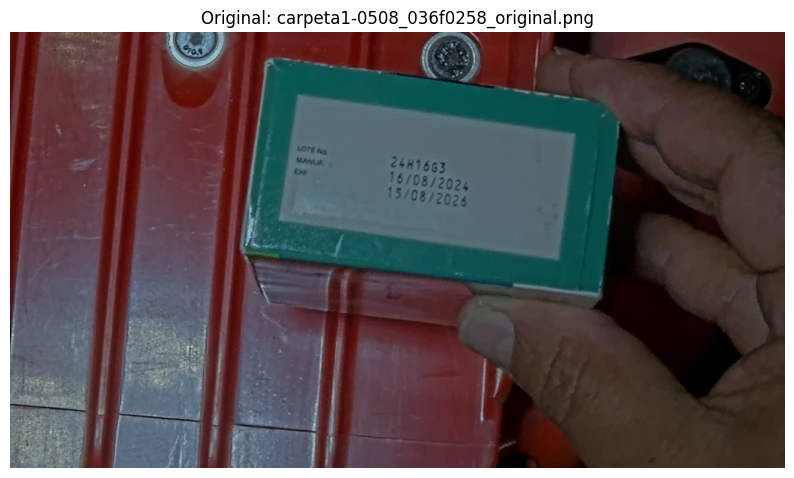

In [6]:
# Imagen de ejemplo: cambia el índice (0-14) o escribe el nombre de archivo para probar otra
IMAGEN_EJEMPLO = rutas_imagenes[0]

# Carpeta donde se guardan las salidas de este ejemplo (NO se toca el dataset original)
carpeta_ejemplo = Path("figuras") / "ejemplo_ocr"
carpeta_ejemplo.mkdir(parents=True, exist_ok=True)

# cv2.imread lee la imagen en formato BGR (el que espera PaddleOCR)
img = cv2.imread(str(IMAGEN_EJEMPLO))
assert img is not None, f"No se pudo leer {IMAGEN_EJEMPLO}"

# Mostramos la imagen original; matplotlib espera RGB, por eso se convierte
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Original: {IMAGEN_EJEMPLO.name}")
plt.axis("off")
plt.show()

In [7]:
# 1) PaddleOCR detecta las zonas con texto y reconoce el contenido de cada una
resultado = paddle_ocr.predict(img)

for res in resultado:
    # res.print()  # (opcional) muestra el resultado completo en consola
    # Imagen con las cajas dibujadas sobre el texto detectado
    res.save_to_img(str(carpeta_ejemplo / "ocr_sin_filtro.png"))
    # JSON con los textos reconocidos (rec_texts), su confianza (rec_scores) y las coordenadas
    res.save_to_json(str(carpeta_ejemplo / "report.json"))

Connecting to https://paddle-model-ecology.bj.bcebos.com/paddlex/PaddleX3.0/fonts/simfang.ttf ...
[==================================================] 100.00%


In [8]:
# 2) Leemos el JSON que acabamos de guardar
ruta_json = carpeta_ejemplo / "report.json"
with open(ruta_json, "r", encoding="utf-8") as f:
    report = json.load(f)

# rec_texts = lista con el texto de cada línea detectada
rec_texts = report["rec_texts"]

# 3) No modificamos ni normalizamos el texto original: así vemos exactamente lo que lee el OCR
texto = "\n".join(str(t) for t in rec_texts)

print("Texto reconocido por el OCR:")
print(texto)
print("-" * 40)

# 4) funcion_maestra busca en ese texto el lote y las fechas (con regex y reglas)
datos = funcion_maestra(texto)

print("Campos extraídos:")
print(json.dumps(datos, indent=4, ensure_ascii=False))

Texto reconocido por el OCR:
010.9
LOTE NG
MANUF
24H16G3
EXF
16/08/2024
15/08/2026
----------------------------------------
Campos extraídos:
{
    "lote": "24H16G3",
    "fecha_fabricacion": "2024-08",
    "fecha_caducidad": "2026-08"
}


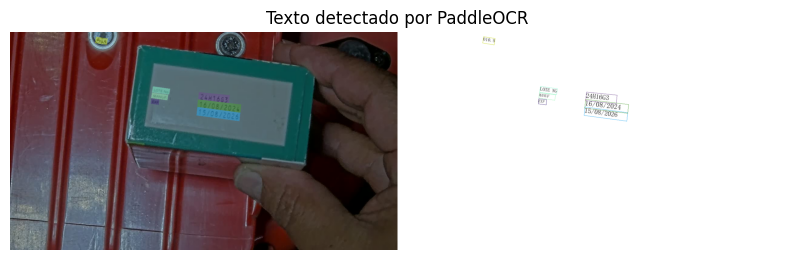

In [9]:
# Mostramos la imagen anotada con las cajas. Es la prueba visual de qué ha detectado el modelo
# (útil para ver si se ha perdido una línea o ha juntado dos).
anotadas = sorted(carpeta_ejemplo.glob("*.png"))
if anotadas:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(cv2.imread(str(anotadas[0])), cv2.COLOR_BGR2RGB))
    plt.title("Texto detectado por PaddleOCR")
    plt.axis("off")
    plt.show()

### 3.2 Función maestra version 2

(mejoras sobre los fallos detectados en las métricas v1)
Cambios respecto a la v1 (cada uno corresponde a un fallo real observado en `metricas_detalle_v1.csv`):
- **Etiqueta `L:`** de una sola letra (`L:2120064`).
- **Meses con letras**: `20/DIC/24`, `DIC 2026` (también separadores mal leídos, como `20>DIC>24`).
- **Fecha pegada a otros dígitos**: `10202411042026/11/03` → se rescata `2026/11/03`.
- **Fecha `mmaaaa` sin separador** (`122026`), solo si no hay ya 2 fechas.
- **Lote solo numérico** (`1248825`), únicamente si el texto no trae ninguna etiqueta de lote, hay un único candidato de 6-10 dígitos y no hay códigos de barras. Se desactiva con `USAR_LOTE_NUMERICO = False`.
- **Prefijo `No.`** pegado al valor (`No.1BAF0434A`).
- **Menos valores inventados**: el lote debe tener ≥ 4 caracteres; se descartan fragmentos de fecha (`12/0`) y, sin etiqueta, solo se aceptan códigos en mayúsculas sin puntos ni guiones (se evita `EE-07484`, `Auf.San.SENASA.000813`).

In [28]:
# funcion_maestra_v2: usa los imports del notebook (re, date, SequenceMatcher)
def funcion_maestra_v2(texto):
 
    resultado = {
        "lote": None,
        "fecha_fabricacion": None,
        "fecha_caducidad": None
    }
 
    # ------------------------------------------------------------------
    # Configuración: para otros idiomas o medicamentos, amplía estos conjuntos
    # (en mayúsculas, sin espacios ni símbolos, y con O en lugar de 0)
    # ------------------------------------------------------------------
    ETIQ_LOTE = ["LOT", "LOTE", "BATCH", "LOTNO", "LOTNR"]
    ETIQ_FAB = ["MANUF", "MANUFACTURED", "MFG", "MFD", "MAN", "FAB", "FABRICACION", "PROD"]
    ETIQ_CAD = ["EXP", "EXF", "EXPIRY", "EXPIRES", "CAD", "CADUCIDAD", "USEBY"]
 
    USAR_LOTE_NUMERICO = True   # False = nunca devuelve un lote que sea solo dígitos sin etiqueta
    MIN_LONG_LOTE = 4   # un lote más corto se descarta (mejor omitir que devolver un valor dudoso)
    MESES = {"ENE": 1, "JAN": 1, "FEB": 2, "MAR": 3, "ABR": 4, "APR": 4, "MAY": 5, "JUN": 6,
             "JUL": 7, "AGO": 8, "AUG": 8, "SEP": 9, "SET": 9, "OCT": 10, "NOV": 11, "DIC": 12, "DEC": 12}
 
    def _sin_prefijo_no(c):
        """'No.1BAF0434A' -> '1BAF0434A'. Quita el 'No.' / 'N°' pegado al valor."""
        if c is None:
            return None
        m = re.match(r"^(?:NO|N°|Nº|NR)[.:°º]+(.+)$", c, re.IGNORECASE)
        if m and len(m.group(1)) >= 4 and any(ch.isdigit() for ch in m.group(1)):
            return m.group(1)
        return c
 
    patron_valor = re.compile(r"[A-Z0-9][A-Z0-9./_-]*", re.IGNORECASE)
    patron_pegado = re.compile(r"^(?:LOTE|LOT|BATCH)[.\-/]?([A-Z0-9][A-Z0-9./_-]*)$", re.IGNORECASE)
 
    patron_fecha = re.compile(
        r"(?<![\d/.\-])(?:"
        r"(?P<y5>\d{4})[/.\-](?P<m5>\d{1,2})[/.\-](?P<d5>\d{1,2})"         # aaaa/mm/dd
        r"|(?P<d>\d{1,2})[/.\-](?P<m1>\d{1,2})[/.\-](?P<y1>\d{4}|\d{2})"   # dd/mm/aaaa o dd/mm/aa
        r"|(?P<y2>\d{4})[/.\-](?P<m2>\d{1,2})"                              # aaaa-mm
        r"|(?P<m3>\d{1,2})[/.\-](?P<y3>\d{4})"                              # mm/aaaa
        r"|(?<![A-Za-z])(?P<m6>\d{1,2})/(?P<y6>\d{2})"                      # mm/aa (solo con "/")
        r"|(?P<m4>\d{1,2}) (?P<y4>\d{4})"                                   # mm aaaa
        r")(?![\d/.\-])"
    )
 
    # ------------------------------------------------------------------
    # 1. LOTE
    # ------------------------------------------------------------------
    lineas = [l.strip() for l in texto.splitlines() if l.strip()]
 
    # Para cada línea se guarda una lista de tokens con sus características:
    # (texto, es_etiqueta_lote, es_valor_lote, valor_pegado_a_etiqueta)
    info_lineas = []
    for linea in lineas:
        partes = re.split(r"[\s:：#=;,]+", linea)
        toks = [p.strip(" .°º") for p in partes if p.strip(" .°º")]
 
        info = []
        for t in toks:
            # ¿Es una etiqueta de lote (aproximada)?
            norm_t = re.sub(r"[^A-Z0-9]", "", t.upper()).replace("0", "O")
            sim_t = 0.0
            if norm_t:
                sim_t = max(SequenceMatcher(None, norm_t, e).ratio() for e in ETIQ_LOTE)
            es_etiqueta = sim_t >= 0.8
 
            # ¿Es un valor de lote válido? Se evalúa el token y, si la etiqueta
            # viene pegada al valor (LOT123), también el valor pegado.
            m_pegado = patron_pegado.match(t)
            pegado = _sin_prefijo_no(m_pegado.group(1)) if m_pegado else None
            t_val = _sin_prefijo_no(t)
 
            flags = []
            for c in (t_val, pegado):
                if c is None:
                    flags.append(False)
                    continue
                norm_c = re.sub(r"[^A-Z0-9]", "", c.upper()).replace("0", "O")
                sim_c = 0.0
                if norm_c:
                    sim_c = max(SequenceMatcher(None, norm_c, e).ratio() for e in ETIQ_LOTE)
                flags.append(
                    patron_valor.fullmatch(c) is not None
                    and len(c) >= MIN_LONG_LOTE
                    and any(ch.isdigit() for ch in c)
                    and patron_fecha.fullmatch(c) is None
                    and not re.fullmatch(r"[\d/.\-]*[/.\-][\d/.\-]*", c)   # "12/0": fragmento de fecha, no un lote
                    and sim_c < 0.8
                )
            es_valor, pegado_valido = flags
 
            info.append((t_val, es_etiqueta, es_valor, pegado if pegado_valido else None))
        info_lineas.append(info)
 
    lote = None
    for i, info in enumerate(info_lineas):
        for k, (t, es_etiqueta, es_valor, pegado) in enumerate(info):
            # Etiqueta pegada al valor: LOT123, LOTE-ABC12, BATCH.5567
            if pegado:
                lote = pegado
                break
 
            if not es_etiqueta:
                continue
 
            # Candidatos por orden de prioridad:
            # a) mismo renglón: después de la etiqueta y luego antes
            # b) líneas siguientes (hasta 3)
            # c) líneas anteriores (hasta 2), valor impreso antes de la etiqueta
            candidatos = [x[0] for x in info[k + 1:] if x[2]]
            candidatos += [x[0] for x in info[:k][::-1] if x[2]]
            for j in range(i + 1, min(i + 4, len(info_lineas))):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]
            for j in range(i - 1, max(i - 3, -1), -1):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]
 
            if candidatos:
                lote = candidatos[0]
                break
 
    # Plan B (1): etiqueta de una sola letra, "L:2120064"
    if lote is None:
        m_l = re.search(r"(?<![A-Za-z0-9])L\s*[:.]\s*([A-Za-z0-9][A-Za-z0-9./_-]*)", texto)
        if m_l:
            c = _sin_prefijo_no(m_l.group(1))
            if (len(c) >= MIN_LONG_LOTE and any(ch.isdigit() for ch in c)
                    and patron_fecha.fullmatch(c) is None):
                lote = c
 
    # Plan B (2): no hay etiqueta, se busca un código que parezca un lote
    # (solo MAYÚSCULAS y dígitos, sin puntos ni guiones: descarta "EE-07484", "C8/2026", "Auf.San.SENASA.000813")
    if lote is None:
        patron_unidad = re.compile(
            r"^\d+([.,]\d+)?(MG|ML|G|MCG|UG|UI|IU|KG|L|MM|CM)$", re.IGNORECASE
        )
        for info in info_lineas:
            for t, es_etiqueta, es_valor, pegado in info:
                if (
                    es_valor
                    and re.fullmatch(r"[A-Z0-9]{5,}", t)
                    and any(c.isalpha() for c in t)
                    and any(c.isdigit() for c in t)
                    and not patron_unidad.match(t)
                ):
                    lote = t
                    break
            if lote:
                break
 
    # Plan B (3): lote solo numérico, únicamente si NO hay ninguna etiqueta de lote en el texto,
    # hay un único candidato de 6-10 dígitos y no hay códigos de barras (11+ dígitos)
    if lote is None:
        hay_etiqueta = any(x[1] for info in info_lineas for x in info)
        nums = {x[0] for info in info_lineas for x in info
                if re.fullmatch(r"\d{6,10}", x[0])
                and not re.fullmatch(r"(0[1-9]|1[0-2])20\d{2}", x[0])}     # descarta mmaaaa
        if USAR_LOTE_NUMERICO and not hay_etiqueta and len(nums) == 1 and not re.search(r"\d{11,}", texto):
            lote = nums.pop()
 
    resultado["lote"] = lote
 
    # ------------------------------------------------------------------
    # 2. FECHAS
    # ------------------------------------------------------------------
    fechas = []  # (año, mes, inicio, fin)
    for m in patron_fecha.finditer(texto):
        g = m.groupdict()
        if g["y5"]:
            mes, anio = int(g["m5"]), g["y5"]
        elif g["d"]:
            mes, anio = int(g["m1"]), g["y1"]
        elif g["y2"]:
            mes, anio = int(g["m2"]), g["y2"]
        elif g["m3"]:
            mes, anio = int(g["m3"]), g["y3"]
        elif g["m6"]:
            mes, anio = int(g["m6"]), g["y6"]
        else:
            mes, anio = int(g["m4"]), g["y4"]
 
        anio = int(anio) + (2000 if len(anio) == 2 else 0)
        if 1 <= mes <= 12 and 2000 <= anio <= 2100:
            fechas.append((anio, mes, m.start(), m.end()))
 
    # (a) mes escrito con letras: 20/DIC/24, DIC 2026
    patron_mes_letra = re.compile(
        r"(?<![A-Za-z])(?:\d{1,2}[/.\-\s>])?(ENE|JAN|FEB|MAR|ABR|APR|MAY|JUN|JUL|AGO|AUG|SEP|SET|OCT|NOV|DIC|DEC)"
        r"[/.\-\s>]*(\d{4}|\d{2})(?!\d)", re.IGNORECASE)
    for m in patron_mes_letra.finditer(texto):
        anio = int(m.group(2)) + (2000 if len(m.group(2)) == 2 else 0)
        if 2000 <= anio <= 2100:
            fechas.append((anio, MESES[m.group(1).upper()], m.start(), m.end()))
 
    # (b) aaaa/mm/dd pegado a dígitos anteriores: "10202411042026/11/03"
    for m in re.finditer(r"(20\d{2})[/.\-](\d{2})[/.\-](\d{2})(?![\d/.\-])", texto):
        if 1 <= int(m.group(2)) <= 12:
            fechas.append((int(m.group(1)), int(m.group(2)), m.start(), m.end()))
 
    # (c) mmaaaa pegado ("122026"): solo si aún hay menos de 2 fechas y no es el lote elegido
    if len({(a, mes) for a, mes, _, _ in fechas}) < 2:
        for m in re.finditer(r"(?<!\d)(0[1-9]|1[0-2])(20\d{2})(?!\d)", texto):
            if m.group(0) != lote:
                fechas.append((int(m.group(2)), int(m.group(1)), m.start(), m.end()))
 
    unicas = sorted({(a, mes) for a, mes, _, _ in fechas})
    fab = cad = None
 
    if len(unicas) >= 2:
        # El orden cronológico no depende de lo bien que el OCR lea las etiquetas
        fab, cad = unicas[0], unicas[-1]
 
    elif len(unicas) == 1:
        a, mes, ini, fin = fechas[0]
        tipo = None
 
        # Palabras cercanas: primero las anteriores a la fecha, luego las posteriores
        antes = re.findall(r"[A-Za-z0-9]+", texto[max(0, ini - 25):ini])[-2:]
        despues = re.findall(r"[A-Za-z0-9]+", texto[fin:fin + 25])[:2]
        for palabra in list(reversed(antes)) + despues:
            if palabra.isdigit():
                continue
            norm_p = re.sub(r"[^A-Z0-9]", "", palabra.upper()).replace("0", "O")
            if not norm_p:
                continue
            sc_cad = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_CAD)
            sc_fab = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_FAB)
            if max(sc_cad, sc_fab) >= 0.5:
                tipo = "cad" if sc_cad >= sc_fab else "fab"
                break
 
        # Sin etiqueta fiable: si es futura se asume caducidad, si no, fabricación
        if tipo is None:
            hoy = date.today()
            tipo = "cad" if (a, mes) >= (hoy.year, hoy.month) else "fab"
 
        if tipo == "cad":
            cad = (a, mes)
        else:
            fab = (a, mes)
 
    resultado["fecha_fabricacion"] = f"{fab[0]}-{fab[1]:02d}" if fab else None
    resultado["fecha_caducidad"] = f"{cad[0]}-{cad[1]:02d}" if cad else None
 
    return resultado

## 4. Filtros de preprocesado
Un único diccionario `FILTROS_TODOS` con todos los pipelines (el `baseline` es la imagen sin filtrar).

### 4.1 Filtros básicos (CLAHE, brillo, gamma, normalización)
Pruebas sencillas que antes se hacían a mano sobre una imagen. `ADAPTATIVE` no se repite aquí: ya está como `adaptativo` en los filtros de Paula (mismos parámetros).

In [10]:
# --- Filtros básicos (antes eran pruebas manuales sueltas con una sola imagen) ---
def pipeline_gris_clahe(img_bgr):
    """Escala de grises + CLAHE (contraste local limitado), sin inversión de polaridad."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris)
    return np.ascontiguousarray(cv2.cvtColor(out, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_clahe_lab(img_bgr):
    """CLAHE solo sobre el canal de luminosidad (LAB): mejora el contraste y conserva el color."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return np.ascontiguousarray(cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR), dtype=np.uint8)

def pipeline_brillo_contraste(img_bgr, alpha=1.3, beta=20):
    """Contraste (alpha) y brillo (beta) globales: out = alpha * img + beta."""
    return np.ascontiguousarray(cv2.convertScaleAbs(img_bgr, alpha=alpha, beta=beta), dtype=np.uint8)

def pipeline_gamma(img_bgr, g=0.6):
    """Corrección gamma: g < 1 aclara la imagen, g > 1 la oscurece."""
    tabla = np.array([(i / 255.0) ** g * 255 for i in range(256)]).astype("uint8")
    return np.ascontiguousarray(cv2.LUT(img_bgr, tabla), dtype=np.uint8)

def pipeline_normalizar(img_bgr):
    """Estira el rango de intensidades a 0-255 (normalización min-max)."""
    return np.ascontiguousarray(cv2.normalize(img_bgr, None, 0, 255, cv2.NORM_MINMAX), dtype=np.uint8)

filtros_basicos = {
    "gris_clahe": pipeline_gris_clahe,
    "clahe_lab": pipeline_clahe_lab,
    "brillo_contraste": pipeline_brillo_contraste,
    "gamma_0.6": pipeline_gamma,
    "normalizar_minmax": pipeline_normalizar,
}

### 4.2 Filtros de Paula (binarización y realces)

In [11]:
def pipeline_sin_filtro(img_bgr):
    return img_bgr

def pipeline_binarizacion_otsu(img_bgr):
    """Binarización automática a blanco y negro con Otsu."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if np.mean(gray) < 127:
        gray = cv2.bitwise_not(gray)
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR)

def pipeline_adaptativo(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    bw = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY, 31, 15)
    return np.ascontiguousarray(cv2.cvtColor(bw, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_mediana_adaptativa(img_bgr):
  """Filtro de mediana suave seguido de umbral adaptativo equilibrado."""
  gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

  # 1. Filtro de mediana con ventana pequeña (3x3) para no emronar los caracteres
  median = cv2.medianBlur(gray, 3)

  # 2. Umbral adaptativo limpio sin inversión forzada brusca
  bw = cv2.adaptiveThreshold(
      median, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 10
  )

  return np.ascontiguousarray(
      cv2.cvtColor(bw, cv2.COLOR_GRAY2BGR), dtype=np.uint8
  )


def pipeline_unsharp_masking(img_bgr):
    """Realce de nitidez basado en la diferencia con la imagen suavizada (Unsharp Mask)."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if np.mean(gray) < 127:
        gray = cv2.bitwise_not(gray)

    # Creamos la versión suavizada (low-pass) y aplicamos la fórmula de realce
    blur = cv2.GaussianBlur(gray, (0, 0), sigmaX=2.0)
    sharpened = cv2.addWeighted(
        gray, 1.5, blur, -0.5, 0
    )  # I_sharp = 1.5*I - 0.5*I_blur

    _, thresh = cv2.threshold(
        sharpened, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    return np.ascontiguousarray(
        cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR), dtype=np.uint8
    )

def pipeline_super_adaptativo(img_bgr):
  """Filtro avanzado: Bilateral (preserva bordes) + Unsharp + Adaptativo."""
  gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
  if np.mean(gray) < 127:
    gray = cv2.bitwise_not(gray)

  # 1. Filtro bilateral: reduce ruido pero mantiene los bordes de las letras súper nítidos
  bilateral = cv2.bilateralFilter(gray, 9, 75, 75)

  # 2. Ligero realce de bordes
  blur = cv2.GaussianBlur(bilateral, (0, 0), sigmaX=1.5)
  sharpened = cv2.addWeighted(bilateral, 1.4, blur, -0.4, 0)

  # 3. Umbral adaptativo para lidiar con fondos irregulares
  bw = cv2.adaptiveThreshold(
      sharpened, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 10
  )

  return np.ascontiguousarray(
      cv2.cvtColor(bw, cv2.COLOR_GRAY2BGR), dtype=np.uint8
  )

filtros_paula = {
    "baseline": pipeline_sin_filtro,
    "adaptativo": pipeline_adaptativo,
    "binary_otsu": pipeline_binarizacion_otsu,
    "mediana_adaptativa": pipeline_mediana_adaptativa,
    "unsharp_masking": pipeline_unsharp_masking,
    "pipeline_super_adaptativo": pipeline_super_adaptativo,
}

In [12]:
def pipeline_unsharp_gris(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (0, 0), sigmaX=2.0)
    out = cv2.addWeighted(gray, 1.5, blur, -0.5, 0)       # sin umbral
    return np.ascontiguousarray(cv2.cvtColor(out, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_contraste_cuantiles(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    lo, hi = np.percentile(gray, (2, 98))
    out = np.clip((gray - lo) * 255 / max(hi - lo, 1), 0, 255).astype(np.uint8)
    return np.ascontiguousarray(cv2.cvtColor(out, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_normaliza_fondo(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    fondo = cv2.GaussianBlur(gray, (0, 0), 25)            # solo el degradado de luz
    out = cv2.divide(gray, fondo, scale=255)
    return np.ascontiguousarray(cv2.cvtColor(out, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_unsharp_2x(img_bgr):
    h, w = img_bgr.shape[:2]
    if max(h, w) < 1500:
        img_bgr = cv2.resize(img_bgr, (w * 2, h * 2), interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(img_bgr, (0, 0), 2.0)
    out = cv2.addWeighted(img_bgr, 1.5, blur, -0.5, 0)
    return np.ascontiguousarray(out, dtype=np.uint8)

filtros_nuevos = {
    "unsharp_gris": pipeline_unsharp_gris,
    "contraste_cuantiles": pipeline_contraste_cuantiles,
    "normaliza_fondo": pipeline_normaliza_fondo,
    "unsharp_2x": pipeline_unsharp_2x,
}

### 4.3 Filtros de Natalia

In [13]:
def pipeline_reescalado_bilateral(img_bgr):
    """Filtro 1: Reescalado 2x + Filtro Bilateral."""
    h, w = img_bgr.shape[:2]
    if max(h, w) < 1500:
        img_bgr = cv2.resize(img_bgr, (w * 2, h * 2), interpolation=cv2.INTER_CUBIC)
    filtered = cv2.bilateralFilter(img_bgr, d=7, sigmaColor=50, sigmaSpace=50)
    return np.ascontiguousarray(filtered, dtype=np.uint8)

def pipeline_polaridad_clahe(img_bgr):
    """Filtro 2: Corrección de polaridad + CLAHE adaptativo."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if np.mean(gray) < 127:
        gray = cv2.bitwise_not(gray)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray_clahe = clahe.apply(gray)
    return np.ascontiguousarray(cv2.cvtColor(gray_clahe, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_blackhat_corregido(img_bgr):
    """Filtro 3: Operación morfológica Black-Hat (Resta para relieve/sombras)."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    enhanced = cv2.subtract(gray, blackhat)
    return np.ascontiguousarray(cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

filtros_natalia = {
    "reescalado_bilateral": pipeline_reescalado_bilateral,
    "polaridad_clahe": pipeline_polaridad_clahe,
    "blackhat_corregido": pipeline_blackhat_corregido,
}

In [14]:
# --- Diccionario único con TODOS los filtros (el baseline es la imagen sin filtrar) ---
FILTROS_TODOS = {**filtros_paula, **filtros_nuevos, **filtros_natalia, **filtros_basicos}
print(len(FILTROS_TODOS), "pipelines:", list(FILTROS_TODOS))

18 pipelines: ['baseline', 'adaptativo', 'binary_otsu', 'mediana_adaptativa', 'unsharp_masking', 'pipeline_super_adaptativo', 'unsharp_gris', 'contraste_cuantiles', 'normaliza_fondo', 'unsharp_2x', 'reescalado_bilateral', 'polaridad_clahe', 'blackhat_corregido', 'gris_clahe', 'clahe_lab', 'brillo_contraste', 'gamma_0.6', 'normalizar_minmax']


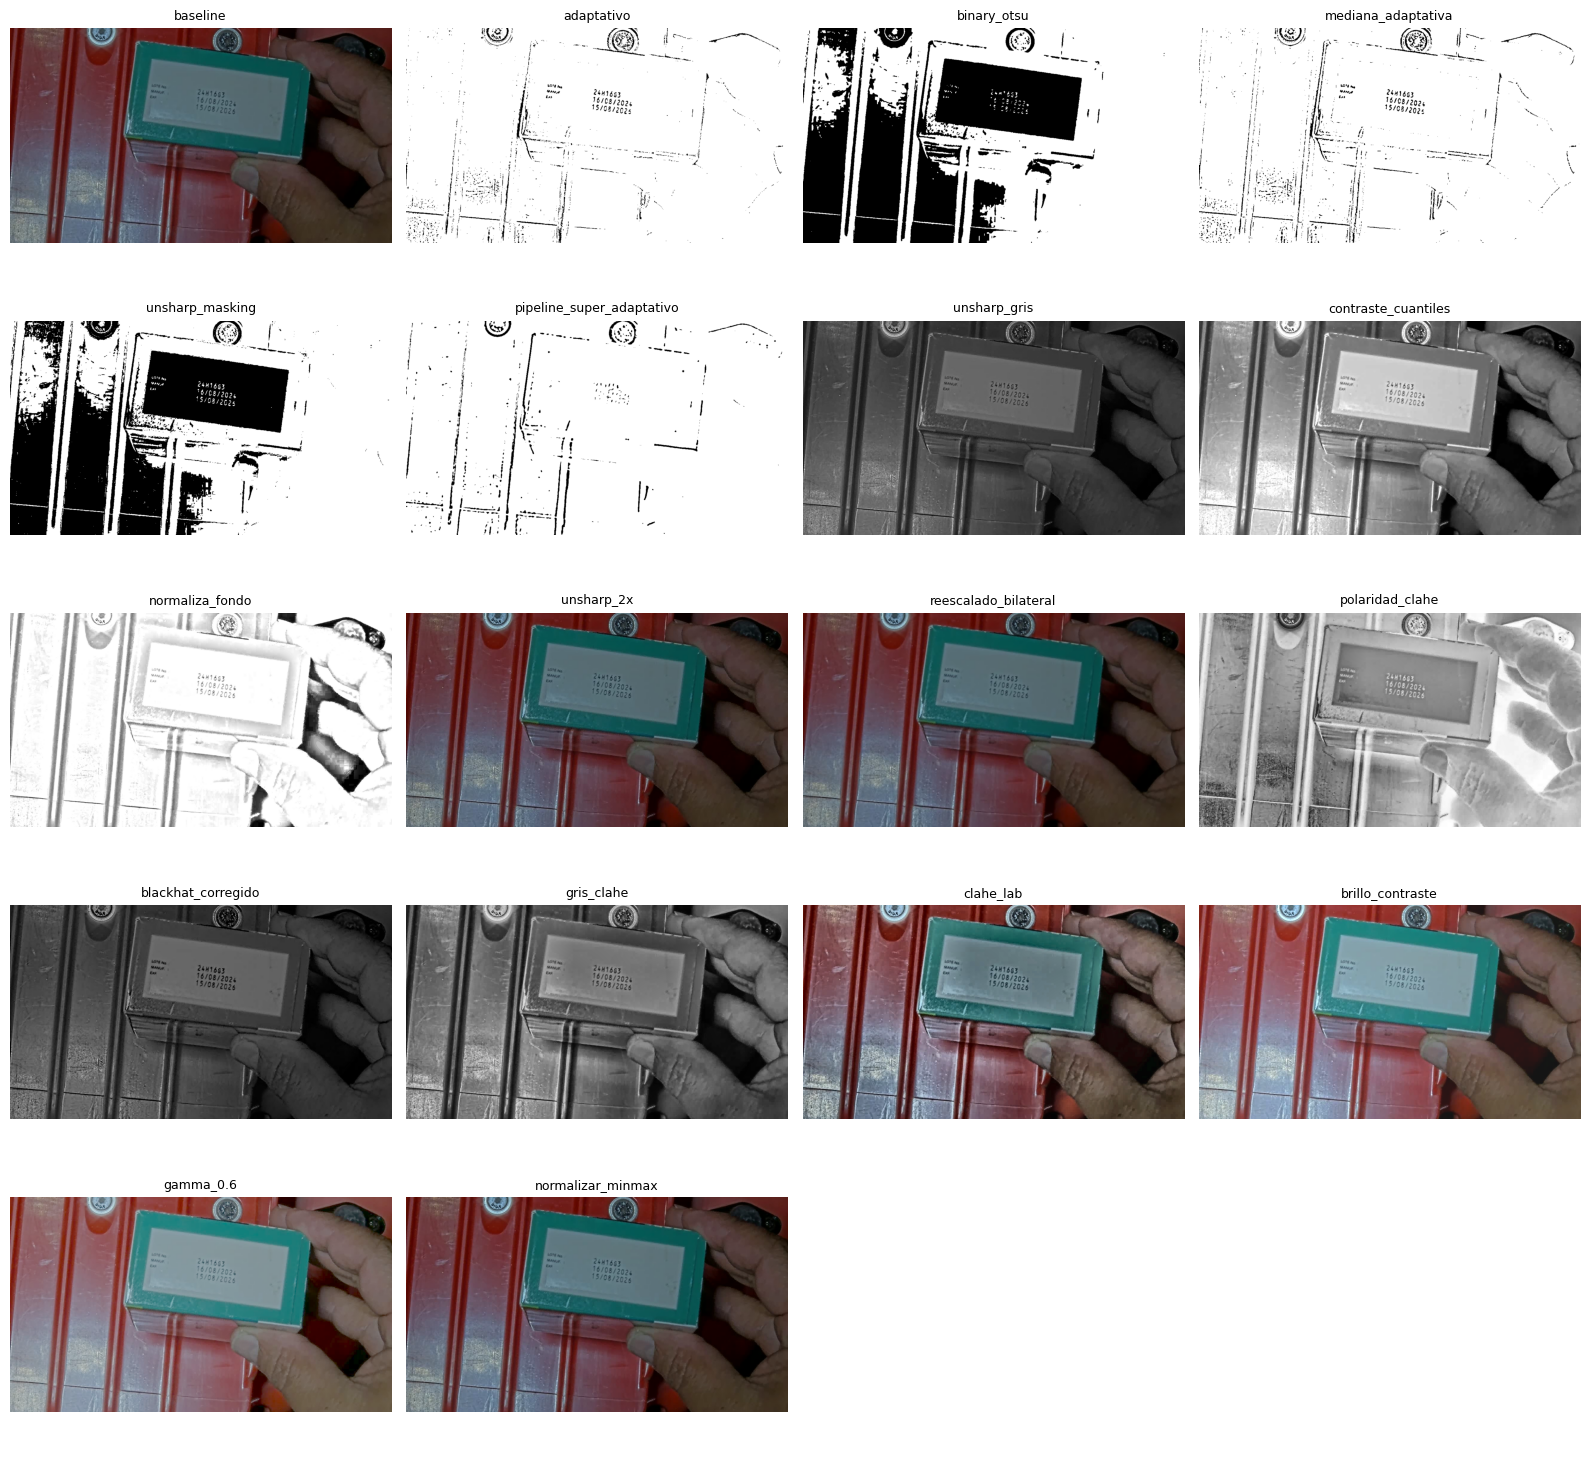

In [15]:
def mostrar_filtros(ruta_imagen, filtros=None, cols=4):
    """Cuadrícula con el resultado de cada filtro sobre una imagen (para el informe)."""
    filtros = filtros or FILTROS_TODOS
    img = cv2.imread(str(ruta_imagen))
    filas = -(-len(filtros) // cols)
    fig, axes = plt.subplots(filas, cols, figsize=(4 * cols, 3 * filas))
    axes = np.ravel(axes)
    for ax in axes: ax.axis("off")
    for ax, (nombre, f) in zip(axes, filtros.items()):
        ax.imshow(cv2.cvtColor(f(img), cv2.COLOR_BGR2RGB)); ax.set_title(nombre, fontsize=9)
    plt.tight_layout(); plt.savefig("figuras/ejemplo_filtros.png", dpi=150); plt.show()

mostrar_filtros(rutas_imagenes[0])

## 5. Experimento completo (filtros × imágenes)
Guarda el texto bruto del OCR y los tiempos. Es **reanudable**: si se corta, al relanzarlo continúa donde se quedó.

In [16]:
# --- Experimento completo: TODOS los filtros x 15 imágenes, con tiempos. REANUDABLE ---
N_PRUEBA = None      # pon 1 para probar con una sola imagen; luego vuelve a None y continúa donde lo dejó

if ARCHIVO_OCR.exists():
    filas = pd.read_csv(ARCHIVO_OCR, dtype=str, keep_default_na=False).to_dict("records")
else:
    filas = []
hechos = {(f["imagen"], f["filtro"]) for f in filas}

# calentamiento (la primera llamada de Paddle es más lenta y falsearía el tiempo del baseline)
_ = extraer_texto_paddle(paddle_ocr, cv2.imread(str(rutas_imagenes[0])))

for ruta in rutas_imagenes[:N_PRUEBA]:
    original = cv2.imread(str(ruta))
    for nombre, aplicar in FILTROS_TODOS.items():
        if (ruta.name, nombre) in hechos:
            continue
        t0 = time.perf_counter()
        filtrada = aplicar(original)
        t1 = time.perf_counter()
        lineas = extraer_texto_paddle(paddle_ocr, filtrada)
        t2 = time.perf_counter()
        filas.append({
            "imagen": ruta.name, "filtro": nombre,
            "texto_ocr": "\n".join(lineas),
            "t_filtro": round(t1 - t0, 3), "t_ocr": round(t2 - t1, 3),
        })
    pd.DataFrame(filas).to_csv(ARCHIVO_OCR, index=False, encoding="utf-8-sig")   # checkpoint tras cada imagen
    print("OK", ruta.name)

print("Filas guardadas:", len(filas), "->", ARCHIVO_OCR)

OK carpeta1-0508_036f0258_original.png
OK carpeta1-0508_0421afbc_original.png
OK carpeta1-0508_0724983f_original.png
OK carpeta1-0508_09d0cb17_original.png
OK carpeta1-0508_0d5e6be4_original.png
OK carpeta2-1408_011935a0_original.png
OK carpeta2-1408_01200be4_original.png
OK carpeta2-1408_0303fac1_original.png
OK carpeta2-1408_03d36f66_original.png
OK carpeta2-1408_0656b9aa_original.png
OK carpeta3-1609_0546ea28_original.png
OK carpeta3-1609_0670c123_original.png
OK carpeta3-1609_089af73d_original.png
OK carpeta3-1609_0914ed75_original.png
OK carpeta3-1609_09a9ac3d_original.png
Filas guardadas: 270 -> muestra_15_imagenes\resultados_ocr_unificado.csv


## 6. Valores reales (ground truth)

In [24]:
# ============================================================
# VALORES REALES (ground truth) -- RELLENAR A MANO MIRANDO LA IMAGEN, NO EL OCR
#   "lote": texto exacto del lote.  Si hay dos lecturas posibles: "ABC123|ABC1Z3"
#   "fab" / "cad": formato AAAA-MM (ej. "2026-08").  "" = el envase NO trae ese dato.
#   "?" = pendiente (el código se detiene si queda alguno)
# ============================================================
GROUND_TRUTH = {
    "carpeta1-0508_036f0258_original.png": {"lote": "24H16G3", "fab": "2024-08", "cad": "2026-08"},  # ejemplo, verificar
    "carpeta1-0508_0421afbc_original.png": {"lote": "932155", "fab": "2024-08", "cad": "2026-08"},
    "carpeta1-0508_0724983f_original.png": {"lote": "BAF0434A", "fab": "2024-09", "cad": "2026-08"},
    "carpeta1-0508_09d0cb17_original.png": {"lote": "20241104", "fab": "2024-11", "cad": "2026-11"},
    "carpeta1-0508_0d5e6be4_original.png": {"lote": "DNf0880B", "fab": "2024-09", "cad": "2026-08"},
    "carpeta2-1408_011935a0_original.png": {"lote": "2120064", "fab": "", "cad": "2026-12"},
    "carpeta2-1408_01200be4_original.png": {"lote": "4031037", "fab": "2024-12", "cad": "2026-12"},
    "carpeta2-1408_0303fac1_original.png": {"lote": "54Y20W", "fab": "", "cad": "2026-12"},
    "carpeta2-1408_03d36f66_original.png": {"lote": "TDTX3", "fab": "2024-01", "cad": "2026-12"},
    "carpeta2-1408_0656b9aa_original.png": {"lote": "30015001", "fab": "2023-12", "cad": "2026-12"},
    "carpeta3-1609_0546ea28_original.png": {"lote": "1248825", "fab": "2025-01", "cad": "2026-09"}, # está upsidedown
    "carpeta3-1609_0670c123_original.png": {"lote": "241217", "fab": "", "cad": "2026-12"},
    "carpeta3-1609_089af73d_original.png": {"lote": "", "fab": "", "cad": ""},   # excluida: lote ilegible
    "carpeta3-1609_0914ed75_original.png": {"lote": "BCY0125002", "fab": "2025-01", "cad": "2026-12"},
    "carpeta3-1609_09a9ac3d_original.png": {"lote": "BCY0125002", "fab": "2025-01", "cad": "2026-12"},
}
EXCLUIDAS = {"carpeta3-1609_089af73d_original.png"}      # no entran en las métricas

## 7. Métricas y comparación
**Qué se compara:** cada filtro frente al **baseline** (imagen original sin filtrar) y frente a la **estrategia en cascada** (baseline primero; otros filtros solo si falta algún campo crítico).

**Métricas:**
- **Accuracy por campo** (lote, fabricación, caducidad) y **global** (los 3 campos): correcto = coincide exactamente, o no hay dato en el envase y no se devuelve nada.
- **Imágenes 3/3**: % de imágenes con los tres campos bien.
- **Omitidos**: hay dato en el envase y no se extrae. **Incorrectos**: se devuelve un valor distinto del real (o inventado). Este último es el error más grave en control de calidad.
- **CER del lote**: distancia de Levenshtein / longitud del lote real (0 = perfecto, 1 = nada que ver).
- **Tiempo medio por imagen** (filtro + OCR).

In [25]:
# ---------- utilidades de evaluación ----------
def levenshtein(a, b):
    if a == b: return 0
    if not a: return len(b)
    if not b: return len(a)
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def _n(x):
    """Normalización única: mayúsculas y sin espacios. Vacío si None/NaN."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return ""
    return re.sub(r"\s+", "", str(x).upper())

def _opciones(gt):
    return [_n(o) for o in str(gt).split("|") if _n(o)]

def resultado_campo(pred, gt):
    p, ops = _n(pred), _opciones(gt)
    if not ops:
        return "correcto" if not p else "falso_positivo"   # no hay dato y se inventa uno
    if not p:
        return "omitido"                                    # hay dato y no se extrae
    return "correcto" if p in ops else "erroneo"            # se extrae un valor distinto

def cer(pred, gt):
    ops, p = _opciones(gt), _n(pred)
    if not ops: return np.nan
    if not p: return 1.0
    return min(1.0, min(levenshtein(p, o) / len(o) for o in ops))

CAMPOS = {"lote": "lote", "fecha_fabricacion": "fab", "fecha_caducidad": "cad"}   # salida funcion_maestra -> clave del GT

# ---------- evaluación de un extractor sobre los textos OCR guardados ----------
def evaluar(df_ocr, extractor):
    pendientes = [i for i, v in GROUND_TRUTH.items() if "?" in v.values() and i not in EXCLUIDAS]
    if pendientes:
        raise ValueError(f"Faltan valores reales en {len(pendientes)} imágenes, p. ej. {pendientes[0]}")
    det = df_ocr[~df_ocr["imagen"].isin(EXCLUIDAS)].copy().reset_index(drop=True)
    det["t_total"] = det["t_filtro"].astype(float) + det["t_ocr"].astype(float)
    ext = det["texto_ocr"].apply(extractor).apply(pd.Series)
    for campo, corto in CAMPOS.items():
        det[campo] = ext[campo].values
        det["res_" + corto] = [resultado_campo(p, GROUND_TRUTH[im][corto]) for p, im in zip(det[campo], det["imagen"])]
    det["cer_lote"] = [cer(p, GROUND_TRUTH[im]["lote"]) for p, im in zip(det["lote"], det["imagen"])]
    res_cols = ["res_lote", "res_fab", "res_cad"]
    det["n_ok"] = sum((det[c] == "correcto").astype(int) for c in res_cols)
    det["n_omit"] = sum((det[c] == "omitido").astype(int) for c in res_cols)
    det["n_incorr"] = sum(det[c].isin(["erroneo", "falso_positivo"]).astype(int) for c in res_cols)
    return det

def resumen(det):
    g = det.groupby("filtro"); n = g.size()
    r = pd.DataFrame({
        "acc_lote": g["res_lote"].apply(lambda s: (s == "correcto").mean()),
        "acc_fab":  g["res_fab"].apply(lambda s: (s == "correcto").mean()),
        "acc_cad":  g["res_cad"].apply(lambda s: (s == "correcto").mean()),
        "acc_global": g["n_ok"].sum() / (3 * n),
        "imgs_3_de_3": g["n_ok"].apply(lambda s: (s == 3).mean()),
        "omitidos": g["n_omit"].sum() / (3 * n),
        "incorrectos": g["n_incorr"].sum() / (3 * n),
        "CER_lote": g["cer_lote"].mean(),
        "tiempo_s": g["t_total"].mean(),
    })
    return r.sort_values("acc_global", ascending=False)

def lleno(x):
    return pd.notna(x) and str(x).strip() != ""

def cascada(det, orden, criticos=("lote", "fecha_caducidad")):
    """Prueba los filtros en 'orden'; se detiene cuando están los campos críticos. Elige el resultado con más campos extraídos.
    No usa el ground truth para decidir; solo mide cuánto aporta encadenar filtros. El tiempo suma los filtros realmente probados."""
    filas = []
    for img, g in det.groupby("imagen"):
        g = g.set_index("filtro"); mejor, t = None, 0.0
        for f in orden:
            r = g.loc[f]; t += r["t_total"]
            n_ext = sum(lleno(r[c]) for c in CAMPOS)
            if mejor is None or n_ext > mejor[0]:
                mejor = (n_ext, r)
            if all(lleno(r[c]) for c in criticos):
                break
        r = mejor[1].copy(); r["filtro"] = "CASCADA"; r["t_total"] = t; r["imagen"] = img
        filas.append(r)
    return pd.DataFrame(filas)

In [26]:
# ---------- TABLA FINAL ----------
df_ocr = pd.read_csv(ARCHIVO_OCR, dtype=str, keep_default_na=False)
det_v1 = evaluar(df_ocr, funcion_maestra)                      # v1 = la función maestra actual

res_filtros = resumen(det_v1)
orden_cascada = ["baseline"] + [f for f in res_filtros.index if f != "baseline"]   # baseline primero, luego por accuracy
det_all = pd.concat([det_v1, cascada(det_v1, orden_cascada)], ignore_index=True)
res = resumen(det_all)

# mejora/empeora frente al baseline (nº de imágenes)
piv = det_all.pivot(index="imagen", columns="filtro", values="n_ok")
res["imgs_mejoran"] = (piv.sub(piv["baseline"], axis=0) > 0).sum()
res["imgs_empeoran"] = (piv.sub(piv["baseline"], axis=0) < 0).sum()

pd.options.display.float_format = "{:.2f}".format
display(res)

b, c = res.loc["baseline"], res.loc["CASCADA"]
print(f"Accuracy global:  baseline {b.acc_global:.2f}  ->  cascada {c.acc_global:.2f}")
print(f"Valores incorrectos: baseline {b.incorrectos:.2f}  ->  cascada {c.incorrectos:.2f}")
print(f"CER del lote:     baseline {b.CER_lote:.2f}  ->  cascada {c.CER_lote:.2f}")
print(f"Tiempo/imagen:    baseline {b.tiempo_s:.1f}s ->  cascada {c.tiempo_s:.1f}s")

res.to_csv(CARPETA_MUESTRA / "metricas_resumen_v1.csv", encoding="utf-8-sig")
det_all.to_csv(CARPETA_MUESTRA / "metricas_detalle_v1.csv", index=False, encoding="utf-8-sig")

,acc_lote,acc_fab,acc_cad,acc_global,imgs_3_de_3,omitidos,incorrectos,CER_lote,tiempo_s,imgs_mejoran,imgs_empeoran
filtro,,,,,,,,,,,
CASCADA,0.64,0.86,0.86,0.79,0.50,0.14,0.07,0.21,71.07,1,0
baseline,0.57,0.86,0.79,0.74,0.50,0.19,0.07,0.28,12.95,0,0
gamma_0.6,0.57,0.86,0.79,0.74,0.43,0.21,0.05,0.30,11.41,1,2
brillo_contraste,0.50,0.79,0.79,0.69,0.36,0.21,0.10,0.38,13.14,1,2
contraste_cuantiles,0.50,0.79,0.71,0.67,0.29,0.24,0.10,0.34,10.97,1,3
unsharp_2x,0.43,0.71,0.71,0.62,0.29,0.26,0.12,0.38,36.10,1,5
normalizar_minmax,0.50,0.71,0.64,0.62,0.36,0.29,0.10,0.40,11.00,0,3
unsharp_gris,0.43,0.79,0.57,0.60,0.21,0.29,0.12,0.37,10.97,0,5
reescalado_bilateral,0.43,0.71,0.64,0.60,0.29,0.33,0.07,0.45,41.34,1,4


Accuracy global:  baseline 0.74  ->  cascada 0.79
Valores incorrectos: baseline 0.07  ->  cascada 0.07
CER del lote:     baseline 0.28  ->  cascada 0.21
Tiempo/imagen:    baseline 13.0s ->  cascada 71.1s


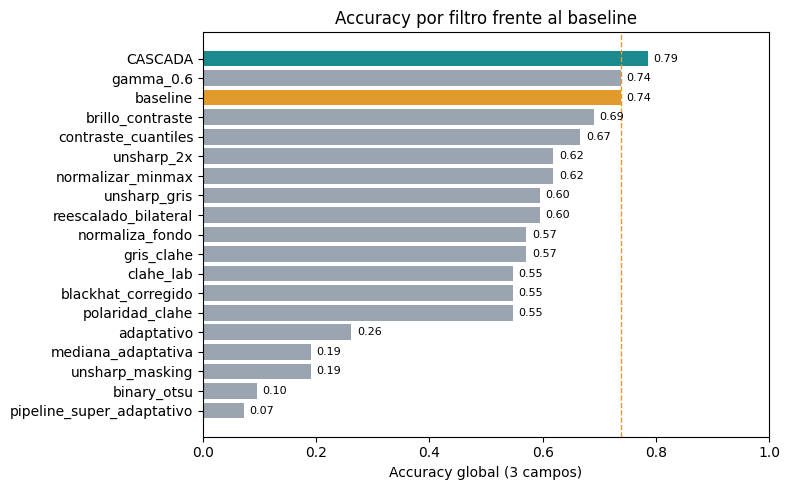

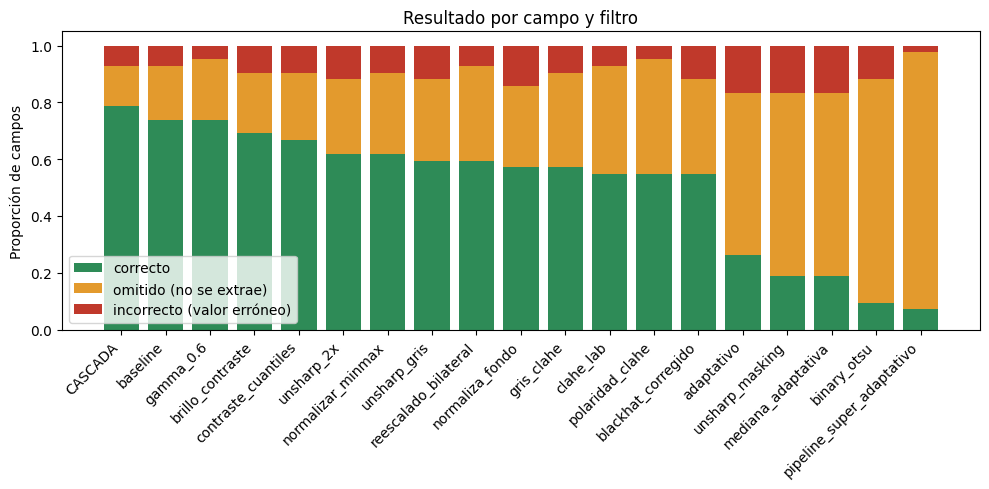

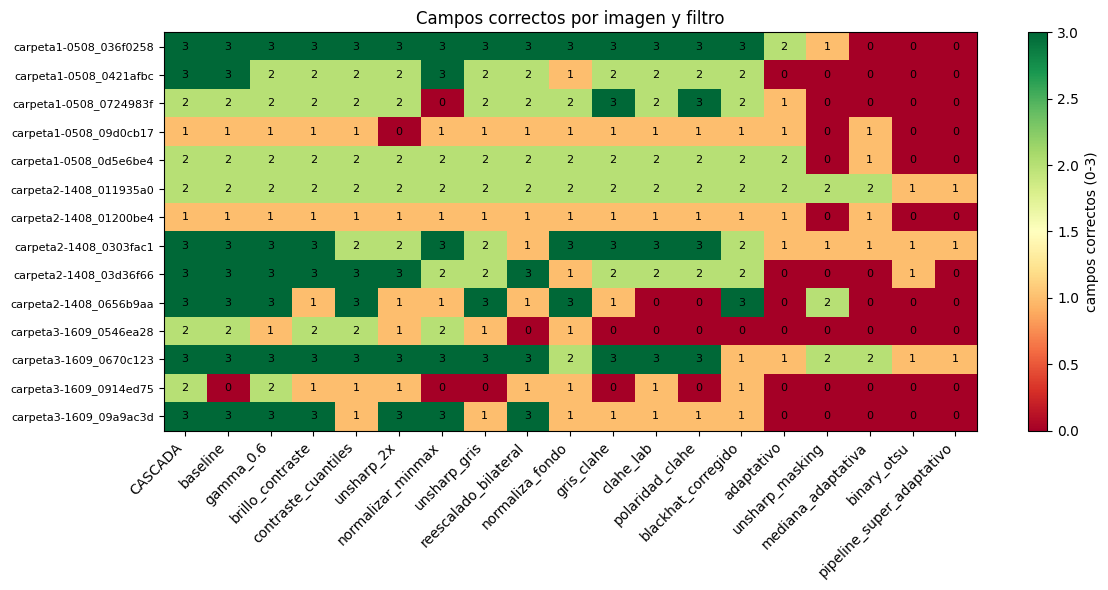

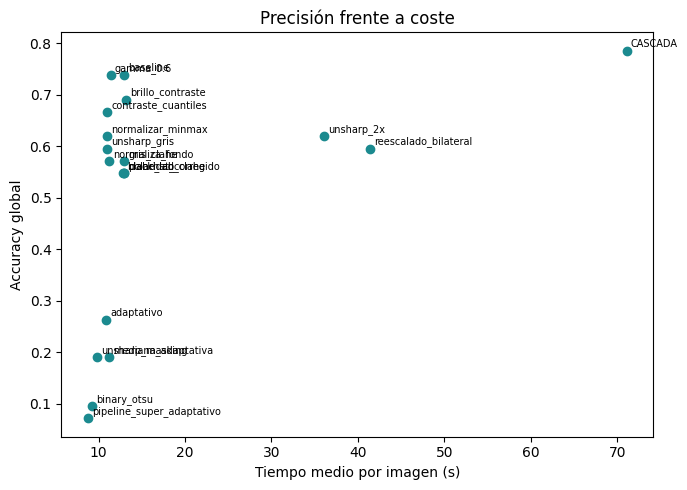

In [27]:
# ---------- GRÁFICAS (se guardan en /figuras para el informe y la presentación) ----------
# 1) Accuracy global por filtro (baseline resaltado)
d = res.sort_values("acc_global")
colores = ["#E39A2D" if f == "baseline" else "#1B8A8F" if f == "CASCADA" else "#9AA5B1" for f in d.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(d.index, d["acc_global"], color=colores)
ax.axvline(res.loc["baseline", "acc_global"], color="#E39A2D", ls="--", lw=1)
ax.set_xlim(0, 1); ax.set_xlabel("Accuracy global (3 campos)")
ax.set_title("Accuracy por filtro frente al baseline")
for y, v in enumerate(d["acc_global"]): ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("figuras/accuracy_por_filtro.png", dpi=200); plt.show()

# 2) Tipos de resultado por filtro (correcto / omitido / incorrecto)
d = res.sort_values("acc_global", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(d.index, d["acc_global"], label="correcto", color="#2E8B57")
ax.bar(d.index, d["omitidos"], bottom=d["acc_global"], label="omitido (no se extrae)", color="#E39A2D")
ax.bar(d.index, d["incorrectos"], bottom=d["acc_global"] + d["omitidos"], label="incorrecto (valor erróneo)", color="#C0392B")
ax.set_ylabel("Proporción de campos"); ax.set_title("Resultado por campo y filtro")
plt.xticks(rotation=45, ha="right"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig("figuras/tipos_error_por_filtro.png", dpi=200); plt.show()

# 3) Heatmap: campos correctos (0-3) por imagen y filtro
cols = list(res.sort_values("acc_global", ascending=False).index)
h = det_all.pivot(index="imagen", columns="filtro", values="n_ok")[cols]
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(h.values.astype(float), cmap="RdYlGn", vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(h))); ax.set_yticklabels([i.replace("_original.png", "") for i in h.index], fontsize=8)
for (i, j), v in np.ndenumerate(h.values): ax.text(j, i, int(v), ha="center", va="center", fontsize=8)
plt.colorbar(im, label="campos correctos (0-3)"); ax.set_title("Campos correctos por imagen y filtro")
plt.tight_layout(); plt.savefig("figuras/heatmap_filtros.png", dpi=200); plt.show()

# 4) Accuracy vs tiempo
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(res["tiempo_s"], res["acc_global"], color="#1B8A8F")
for f, r in res.iterrows(): ax.annotate(f, (r["tiempo_s"], r["acc_global"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Tiempo medio por imagen (s)"); ax.set_ylabel("Accuracy global"); ax.set_title("Precisión frente a coste")
plt.tight_layout(); plt.savefig("figuras/accuracy_vs_tiempo.png", dpi=200); plt.show()

### 7.1 Comparación v1 vs v2 (misma salida del OCR, solo cambia la extracción)
No hace falta repetir el OCR: se reutiliza `df_ocr`. Mejora de `funcion_maestra_v2` aislada del efecto de los filtros.

,acc_v1,acc_v2,incorrectos_v1,incorrectos_v2,CER_lote_v1,CER_lote_v2,mejora_acc
filtro,,,,,,,
CASCADA,0.79,0.90,0.07,0.05,0.21,0.09,0.12
baseline,0.74,0.86,0.07,0.05,0.28,0.16,0.12
gamma_0.6,0.74,0.83,0.05,0.07,0.30,0.17,0.10
brillo_contraste,0.69,0.79,0.10,0.12,0.38,0.24,0.10
contraste_cuantiles,0.67,0.76,0.10,0.12,0.34,0.18,0.10
normalizar_minmax,0.62,0.76,0.10,0.10,0.40,0.27,0.14
unsharp_gris,0.60,0.71,0.12,0.14,0.37,0.23,0.12
gris_clahe,0.57,0.69,0.10,0.12,0.40,0.27,0.12
unsharp_2x,0.62,0.69,0.12,0.12,0.38,0.26,0.07


baseline accuracy 0.74 -> 0.86 | incorrectos 0.07 -> 0.05 | CER lote 0.28 -> 0.16
CASCADA  accuracy 0.79 -> 0.90 | incorrectos 0.07 -> 0.05 | CER lote 0.21 -> 0.09


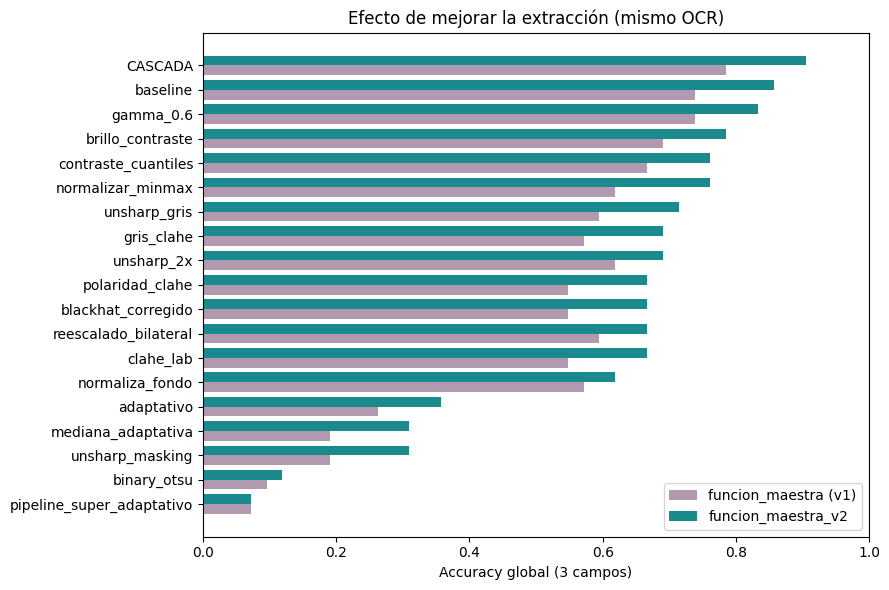

In [31]:
# ---------- COMPARACIÓN v1 vs v2 (sin repetir el OCR) ----------
det_v2 = evaluar(df_ocr, funcion_maestra_v2)
orden_v2 = ["baseline"] + [f for f in resumen(det_v2).index if f != "baseline"]
det_v2_all = pd.concat([det_v2, cascada(det_v2, orden_v2)], ignore_index=True)
res_v2 = resumen(det_v2_all)

comp = pd.DataFrame({
    "acc_v1": res["acc_global"], "acc_v2": res_v2["acc_global"],
    "incorrectos_v1": res["incorrectos"], "incorrectos_v2": res_v2["incorrectos"],
    "CER_lote_v1": res["CER_lote"], "CER_lote_v2": res_v2["CER_lote"],
})
comp["mejora_acc"] = comp["acc_v2"] - comp["acc_v1"]
comp = comp.sort_values("acc_v2", ascending=False)
pd.options.display.float_format = "{:.2f}".format
display(comp)

for nombre in ("baseline", "CASCADA"):
    c = comp.loc[nombre]
    print(f"{nombre:8s} accuracy {c.acc_v1:.2f} -> {c.acc_v2:.2f} | incorrectos {c.incorrectos_v1:.2f} -> {c.incorrectos_v2:.2f} | CER lote {c.CER_lote_v1:.2f} -> {c.CER_lote_v2:.2f}")

comp.to_csv(CARPETA_MUESTRA / "comparacion_v1_v2.csv", encoding="utf-8-sig")
det_v2_all.to_csv(CARPETA_MUESTRA / "metricas_detalle_v2.csv", index=False, encoding="utf-8-sig")

# Gráfica: accuracy por filtro, v1 frente a v2
d = comp.sort_values("acc_v2")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y - 0.2, d["acc_v1"], height=0.4, label="funcion_maestra (v1)", color="#B19AB0")
ax.barh(y + 0.2, d["acc_v2"], height=0.4, label="funcion_maestra_v2", color="#1B8A8F")
ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_xlim(0, 1)
ax.set_xlabel("Accuracy global (3 campos)"); ax.set_title("Efecto de mejorar la extracción (mismo OCR)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figuras/accuracy_v1_vs_v2.png", dpi=200); plt.show()

## 7.2 Conclusiones

**Muestra:** 14 imágenes (42 campos: lote, fabricación y caducidad). Se excluye `089af73d` por lote ilegible. Con tan pocas imágenes, una sola cambia la accuracy de un campo en 0,07 y la global en 0,02, así que las diferencias pequeñas son indicativas, no concluyentes.

### Resultados con la función maestra original (v1)

- **Ningún filtro mejora al baseline.** El baseline (imagen sin filtrar) logra una accuracy global de **0,74** (31 de 42 campos), con 0,57 en lote, 0,86 en fabricación y 0,79 en caducidad. `gamma_0.6` lo iguala (0,74) pero no lo supera. Ningún otro filtro mejora al baseline en más de 1 imagen, y todos empeoran entre 2 y 13.
- **La binarización es lo peor.** `adaptativo` (0,26), `unsharp_masking` (0,19), `mediana_adaptativa` (0,19), `binary_otsu` (0,10) y `pipeline_super_adaptativo` (0,07) pierden entre el 57 % y el 90 % de los campos por omisión: al pasar a blanco y negro, el detector deja de encontrar el texto.
- **Los realces suaves tampoco ayudan.** Los filtros que conservan la intensidad (`brillo_contraste` 0,69, `contraste_cuantiles` 0,67, `unsharp_2x` y `normalizar_minmax` 0,62) y los de contraste local o morfológicos (`clahe_lab`, `polaridad_clahe`, `blackhat_corregido`, 0,55) quedan por debajo del baseline. El reescalado 2x (`unsharp_2x`, `reescalado_bilateral`) cuesta 36-41 s por imagen frente a 13 s sin mejorar nada.
- **El lote es el campo más difícil** (0,57 en el baseline, frente a 0,86 y 0,79 de las fechas).
- **Cascada** (baseline primero y otros filtros solo si falta lote o caducidad): 0,79 frente a 0,74, es decir, +0,05. Equivale a una sola imagen, con un coste de **71 s por imagen frente a 13 s** (5,5 veces más). No compensa para un uso en tiempo real.
- **Valores incorrectos:** en el baseline y la cascada son bajos (0,07), pero no nulos. Un valor erróneo es más grave que uno omitido, porque no se detecta.

### Efecto de `funcion_maestra_v2` (mismo texto del OCR, solo cambia la extracción)

- **Mejora casi todos los pipelines**, entre +0,05 y +0,14 de accuracy. En el baseline sube de **0,74 a 0,86** (+5 campos) y el CER del lote baja de 0,28 a 0,16. En la cascada sube de 0,79 a 0,90 y su CER baja de 0,21 a 0,09. Solo `binary_otsu` y `pipeline_super_adaptativo` apenas cambian, porque el OCR casi no les devuelve texto.
- **La conclusión sobre los filtros no cambia.** El baseline sigue primero entre los filtros individuales, `gamma_0.6` es segundo (0,83) y la binarización sigue siendo la peor. La mejora vino de arreglar la extracción, no del preprocesado: un cambio en la función maestra (+0,12 en el baseline) aporta más que cualquier filtro.
- **Qué corrige la v2:** la etiqueta `L:`, meses con letras (`20/DIC/24`), fechas pegadas a otros dígitos, lotes solo numéricos y el prefijo `No.`. También evita devolver como lote fragmentos de fecha o números de registro (`EE-07484`).
- **Qué sigue fallando en el baseline** (6 campos de 42): confusiones del OCR entre `B`, `0` y `8` en el lote (`0724983f`, `0d5e6be4`); un lote pegado a un icono en `09d0cb17`; y `0914ed75`, donde el OCR casi no lee nada. Ningún cambio en la regex los arregla.
- **Atención a los valores incorrectos:** bajan en el baseline y en la cascada (0,07 a 0,05), pero **suben ligeramente en 10 de las 19 filas** (por ejemplo `gamma_0.6`, de 0,05 a 0,07, o `normaliza_fondo`, de 0,14 a 0,17). La v2 recupera más campos, pero en textos ruidosos también puede devolver algún valor equivocado.

### Limitaciones

- La versión 2 de la función maestra se ha diseñado y cambiado mirando los fallos de estas 15 imágenes que probamos con v1, así que su mejora es **optimista**. Hay que validarla con imágenes nuevas etiquetadas para ver si realmente funciona mejor.
- Los ground truth los tiene que revisar alguien más por si me he equivocado
- Los tiempos son de un único ordenador (CPU). En la Raspberry Pi 5 serán mayores.

### Próximos pasos que se desprenden

1. Validar la v2 en un conjunto de test con imágenes nuevas.
2. Probar orientación y parámetros del detector de PaddleOCR (no más filtros).
3. Guardar las confianzas del OCR para marcar lecturas dudosas para revisión manual.
4. Evaluar una cascada reducida (baseline más 1 o 2 filtros) para recortar el tiempo (ya no nos hace falta probar TODOS los filtros que hemos hehco cada vez, seleccionar los mejores)